# Performance analysis

This notebook measures the time and memory used by the algorithms and data structures in this project.
All tests use the real dataset `books.csv` (10,000 books).

1. Sorting: bubble sort, insertion sort, merge sort
2. Trees: BST compared with the balanced AVL tree
3. Tree traversals: in-order, pre-order, post-order
4. Searching: linear search, binary search, BST, AVL tree, hash table
5. Memory used by each data structure

Each time shown is the best of several runs.

In [1]:
import random
import time
import tracemalloc

import matplotlib.pyplot as plt
import pandas as pd

from algorithms.binary_search import binary_search
from algorithms.bubble_sort import bubble_sort
from algorithms.insertion_sort import insertion_sort
from algorithms.linear_search import linear_search
from algorithms.merge_sort import merge_sort
from algorithms.tree_traversal import inorder, preorder, postorder
from book import load_books
from data_structures.AVL import AVLTree
from data_structures.BST import BST
from data_structures.hash_table import HashTable
from data_structures.linked_list import LinkedList

%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

REPEATS = 3


def measure(func, repeats=REPEATS):
    best, result = float("inf"), None
    for _ in range(repeats):
        start = time.perf_counter()
        result = func()
        best = min(best, (time.perf_counter() - start) * 1000)
    return result, best


def peak_memory_kb(func):
    tracemalloc.start()
    func()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024


def ranking(times, unit="ms"):
    column = f"Time ({unit})"
    df = pd.DataFrame({column: times}).sort_values(column)
    df["Times slower"] = (df[column] / df[column].min()).round(1)
    df.index.name = "Algorithm"
    return df.round(3)

## Load the dataset

In [2]:
books, load_ms = measure(lambda: load_books("books.csv"), repeats=1)
with_isbn = [b for b in books if b.isbn]
print(f"Loaded {len(books)} books in {load_ms:.1f} ms, {len(with_isbn)} of them have an ISBN")
pd.DataFrame([vars(b) for b in books[:5]])

Loaded 10000 books in 47.7 ms, 9300 of them have an ISBN


,isbn,title,author,year
0,0439023483,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,2008
1,0439554934,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",1997
2,0316015849,"Twilight (Twilight, #1)",Stephenie Meyer,2005
3,0061120081,To Kill a Mockingbird,Harper Lee,1960
4,0743273567,The Great Gatsby,F. Scott Fitzgerald,1925


## 1. Sorting

### Time for different input sizes

The books are sorted by publication year. Bubble sort and insertion sort are O(n²),
so they are tested on the first 100 to 2000 books only.

In [3]:
sorters = {
    "Bubble sort": lambda data: bubble_sort(list(data)),
    "Insertion sort": lambda data: insertion_sort(list(data)),
    "Merge sort": lambda data: merge_sort(data),
}

SORT_SIZES = [100, 250, 500, 1000, 1500, 2000]
sort_results = {}
for n in SORT_SIZES:
    sample = books[:n]
    sort_results[n] = {name: measure(lambda: sorter(sample))[1] for name, sorter in sorters.items()}

sort_df = pd.DataFrame(sort_results).T
sort_df.index.name = "Books"
sort_df.round(2)

,Bubble sort,Insertion sort,Merge sort
Books,,,
100,0.53,0.28,0.13
250,3.22,1.51,0.39
500,13.85,6.43,0.83
1000,55.41,23.93,1.83
1500,122.76,51.65,2.83
2000,222.15,93.14,4.15


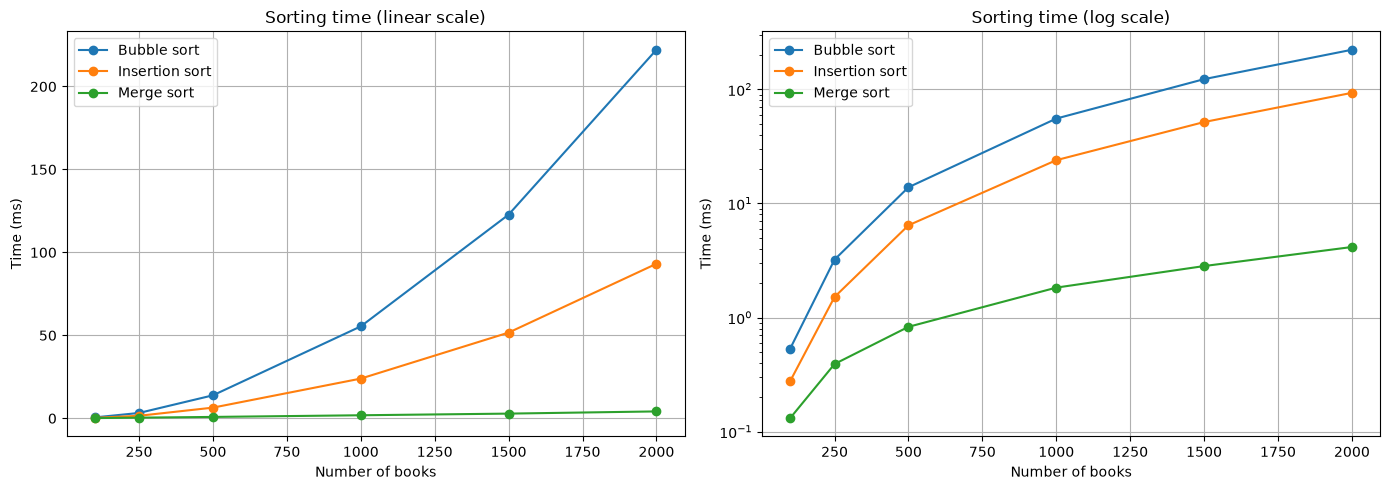

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name in sort_df.columns:
    ax1.plot(sort_df.index, sort_df[name], marker="o", label=name)
    ax2.plot(sort_df.index, sort_df[name], marker="o", label=name)
ax1.set_title("Sorting time (linear scale)")
ax2.set_title("Sorting time (log scale)")
ax2.set_yscale("log")
for ax in (ax1, ax2):
    ax.set_xlabel("Number of books")
    ax.set_ylabel("Time (ms)")
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
print("Ranking for 2000 books:")
ranking(sort_results[2000])

Ranking for 2000 books:


,Time (ms),Times slower
Algorithm,,
Merge sort,4.150,1.0
Insertion sort,93.142,22.4
Bubble sort,222.150,53.5


When the input size doubles, an O(n²) algorithm should take about 4 times longer,
and an O(n log n) algorithm a little over 2 times longer.

In [6]:
(sort_df.loc[2000] / sort_df.loc[1000]).round(2).to_frame("time(2000) / time(1000)")

,time(2000) / time(1000)
Bubble sort,4.01
Insertion sort,3.89
Merge sort,2.27


### Time for different input types

The same 2000 books are sorted in three different starting orders:
random (as in the CSV), already sorted, and reversed.

In [7]:
sample = books[:2000]
inputs = {
    "Random": sample,
    "Already sorted": merge_sort(sample),
    "Reversed": merge_sort(sample)[::-1],
}

type_df = pd.DataFrame({
    input_name: {name: measure(lambda: sorter(data))[1] for name, sorter in sorters.items()}
    for input_name, data in inputs.items()
})
type_df.index.name = "Algorithm"
type_df.round(2)

,Random,Already sorted,Reversed
Algorithm,,,
Bubble sort,222.37,0.18,260.16
Insertion sort,93.21,0.25,203.80
Merge sort,3.94,2.55,2.86


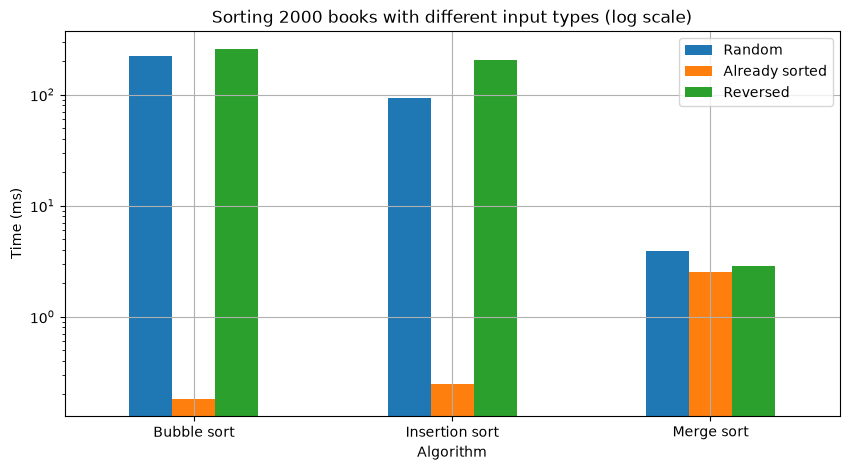

In [8]:
ax = type_df.plot.bar(rot=0, logy=True)
ax.set_title("Sorting 2000 books with different input types (log scale)")
ax.set_ylabel("Time (ms)")
plt.show()

On already sorted data, bubble sort and insertion sort finish in one pass, which takes O(n) time.
Reversed data is their worst case. Merge sort takes almost the same time for every input type.

### Merge sort on the full dataset

In [9]:
_, full_ms = measure(lambda: merge_sort(books))
print(f"Merge sort sorted all {len(books)} books in {full_ms:.2f} ms")

Merge sort sorted all 10000 books in 24.98 ms


### Memory used by sorting

Peak extra memory while sorting 2000 books. Bubble sort and insertion sort work in place.
Merge sort creates new lists when it merges, so it needs O(n) extra memory.

In [10]:
sample = books[:2000]
sort_memory = {
    "Bubble sort": peak_memory_kb(lambda: bubble_sort(sample[:])),
    "Insertion sort": peak_memory_kb(lambda: insertion_sort(sample[:])),
    "Merge sort": peak_memory_kb(lambda: merge_sort(sample)),
}
copy_kb = peak_memory_kb(lambda: sample[:])
sort_memory = {name: kb - copy_kb for name, kb in sort_memory.items()}
pd.DataFrame({"Extra memory (KB)": sort_memory}).round(1)

,Extra memory (KB)
Bubble sort,1.1
Insertion sort,0.0
Merge sort,21.9


## 2. BST compared with the AVL tree

A normal BST can become unbalanced. If the books are inserted in sorted order, the BST turns
into a long chain, and searching becomes O(n). The AVL tree rotates its nodes after every insert,
so its height stays close to log₂(n).

In [11]:
n_sorted = 2000
sorted_books = merge_sort(with_isbn, key=lambda b: b.isbn)[:n_sorted]
random_books = with_isbn


def build(tree_class, data):
    tree = tree_class()
    for b in data:
        tree.insert(b)
    return tree


rows = []
for order, data in [("Random order", random_books), ("Sorted order", sorted_books)]:
    for tree_class in (BST, AVLTree):
        tree, build_ms = measure(lambda: build(tree_class, data), repeats=1)
        targets = random.Random(1).sample(data, 500)
        _, search_ms = measure(lambda: [tree.search(b.isbn) for b in targets])
        rows.append({
            "Insert order": order,
            "Tree": tree_class.__name__,
            "Books": len(data),
            "Height": tree.get_height(),
            "Build time (ms)": round(build_ms, 2),
            "Avg search (µs)": round(search_ms / len(targets) * 1000, 2),
        })

tree_df = pd.DataFrame(rows)
tree_df

,Insert order,Tree,Books,Height,Build time (ms),Avg search (µs)
0,Random order,BST,9300,31,8.96,0.89
1,Random order,AVLTree,9300,16,36.11,0.66
2,Sorted order,BST,2000,2000,81.65,44.91
3,Sorted order,AVLTree,2000,11,6.30,0.51


With random order both trees are short, so they are almost equally fast. With sorted order the BST
height is equal to the number of books, and searching in it becomes much slower,
while the AVL tree stays short and fast.

## 3. Tree traversals

All three traversals visit every node once, so they all take O(n) time. They differ only in the
order in which the nodes are visited:

- **In-order** (left, node, right) gives the books sorted by ISBN
- **Pre-order** (node, left, right) visits the root first
- **Post-order** (left, right, node) visits the root last

The traversals are recursive, so they also need O(h) memory for the call stack, where h is the tree height.

In [12]:
traversals = {"In-order": inorder, "Pre-order": preorder, "Post-order": postorder}
TRAVERSAL_SIZES = [1000, 2500, 5000, len(with_isbn)]

trav_results = {}
for n in TRAVERSAL_SIZES:
    tree = build(AVLTree, with_isbn[:n])
    trav_results[n] = {name: measure(lambda: func(tree.root))[1] for name, func in traversals.items()}

trav_df = pd.DataFrame(trav_results).T
trav_df.index.name = "Books"
trav_df.round(3)

,In-order,Pre-order,Post-order
Books,,,
1000,0.082,0.082,0.080
2500,0.195,0.202,0.202
5000,0.398,0.402,0.415
9300,0.782,0.786,0.748


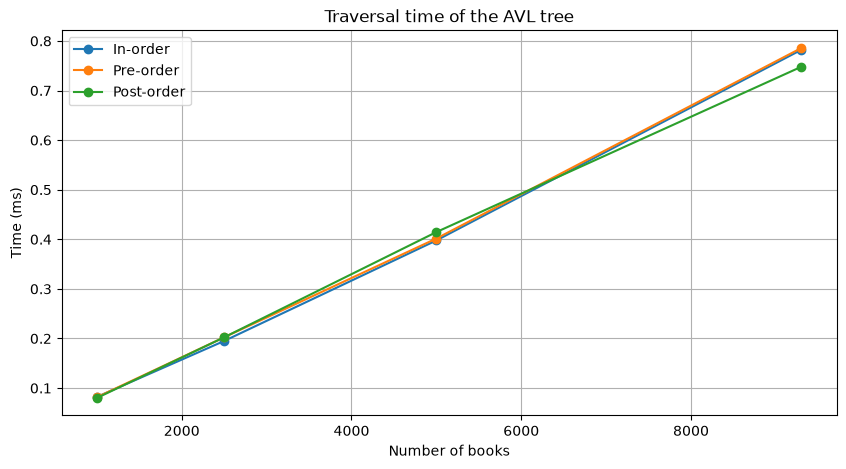

In [13]:
for name in trav_df.columns:
    plt.plot(trav_df.index, trav_df[name], marker="o", label=name)
plt.title("Traversal time of the AVL tree")
plt.xlabel("Number of books")
plt.ylabel("Time (ms)")
plt.legend()
plt.show()

In [14]:
tree = build(AVLTree, with_isbn)
first_isbns = pd.DataFrame({name: [b.isbn for b in func(tree.root)[:5]] for name, func in traversals.items()})
first_isbns.index.name = "Position"
print("First 5 ISBNs visited by each traversal:")
first_isbns

First 5 ISBNs visited by each traversal:


,In-order,Pre-order,Post-order
Position,,,
0,000100039X,0451524934,000100039X
1,0001713221,0316769177,000224618X
2,000224618X,0064410935,0002310015
3,0002310015,0061120081,0001713221
4,0002314576,0060764899,0006161413


## 4. Searching by ISBN

Each algorithm looks up 1,000 random ISBNs that exist and 1,000 that don't exist.

In [15]:
linked = LinkedList()
for b in books:
    linked.append(b)
bst = build(BST, with_isbn)
avl = build(AVLTree, with_isbn)
table = HashTable(size=16384)
for b in with_isbn:
    table.insert(b.isbn, b)
array = merge_sort(with_isbn, key=lambda b: b.isbn)

rng = random.Random(42)
hits = [b.isbn for b in rng.sample(with_isbn, 1000)]
misses = [f"X{i:09d}" for i in range(1000)]

searchers = {
    "Linear search (LinkedList)": lambda isbn: linear_search(linked, isbn),
    "Binary search (array)": lambda isbn: binary_search(array, isbn),
    "BST search": bst.search,
    "AVL tree search": avl.search,
    "Hash table lookup": table.get,
}

rows = {}
for name, search in searchers.items():
    found, hit_ms = measure(lambda: sum(1 for q in hits if search(q) is not None))
    assert found == len(hits)
    _, miss_ms = measure(lambda: [search(q) for q in misses])
    rows[name] = {
        "Found: avg µs": hit_ms / len(hits) * 1000,
        "Missing: avg µs": miss_ms / len(misses) * 1000,
    }

search_df = pd.DataFrame(rows).T
search_df.index.name = "Algorithm"
search_df.round(2)

,Found: avg µs,Missing: avg µs
Algorithm,,
Linear search (LinkedList),128.52,260.67
Binary search (array),1.12,1.24
BST search,0.92,0.82
AVL tree search,0.68,0.69
Hash table lookup,0.68,0.66


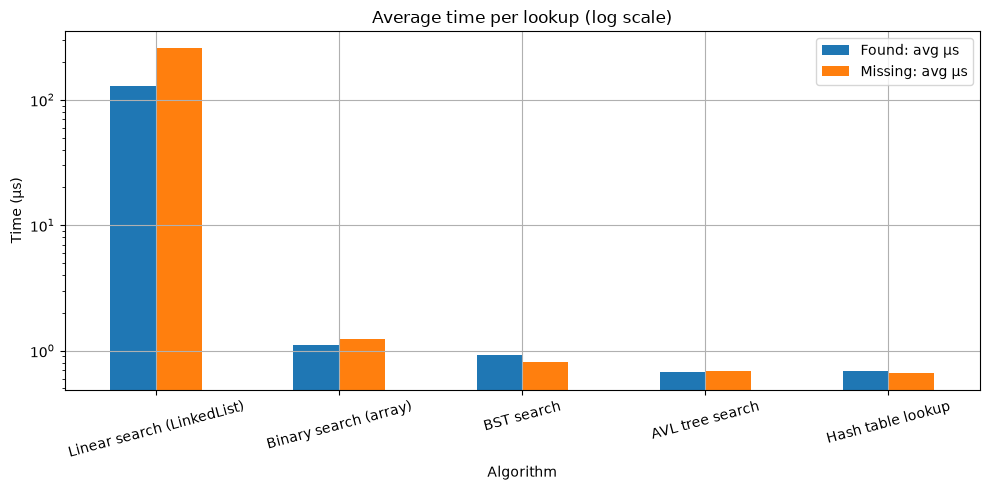

In [16]:
ax = search_df.plot.bar(rot=15, logy=True)
ax.set_title("Average time per lookup (log scale)")
ax.set_ylabel("Time (µs)")
plt.tight_layout()
plt.show()

In [17]:
print("Ranking by average time per successful lookup:")
ranking(search_df["Found: avg µs"].to_dict(), unit="µs")

Ranking by average time per successful lookup:


,Time (µs),Times slower
Algorithm,,
AVL tree search,0.680,1.0
Hash table lookup,0.685,1.0
BST search,0.916,1.3
Binary search (array),1.120,1.6
Linear search (LinkedList),128.523,188.9


## 5. Memory used by the data structures

Memory needed to store all books with an ISBN in each structure.
The book objects themselves are shared, so only the structure is counted.

In [18]:
def make_linked():
    ll = LinkedList()
    for b in with_isbn:
        ll.append(b)
    return ll


def make_table():
    t = HashTable(size=16384)
    for b in with_isbn:
        t.insert(b.isbn, b)
    return t


structure_memory = {
    "Array (Python list)": peak_memory_kb(lambda: list(with_isbn)),
    "LinkedList": peak_memory_kb(make_linked),
    "BST": peak_memory_kb(lambda: build(BST, with_isbn)),
    "AVL tree": peak_memory_kb(lambda: build(AVLTree, with_isbn)),
    "Hash table": peak_memory_kb(make_table),
}
memory_df = pd.DataFrame({"Memory (KB)": structure_memory}).sort_values("Memory (KB)").round(1)
memory_df["Bytes per book"] = (memory_df["Memory (KB)"] * 1024 / len(with_isbn)).round(1)
memory_df

,Memory (KB),Bytes per book
Array (Python list),72.7,8.0
LinkedList,799.5,88.0
BST,872.2,96.0
AVL tree,944.8,104.0
Hash table,1788.0,196.9


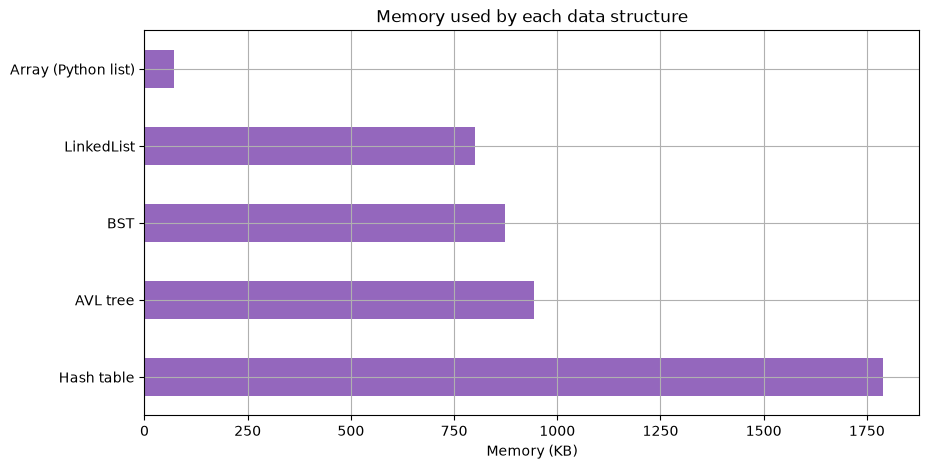

In [19]:
ax = memory_df["Memory (KB)"].plot.barh(color="tab:purple")
ax.set_title("Memory used by each data structure")
ax.set_xlabel("Memory (KB)")
ax.invert_yaxis()
plt.show()

## Summary

**Sorting.** Bubble sort and insertion sort both take O(n²) time and O(1) extra memory, because they sort
the list in place. When the number of books doubles, their running time grows roughly fourfold. Bubble sort
is the slowest, and insertion sort is about twice as fast, but neither is practical for 10,000 books.
On data that is already sorted, both of them finish in a single pass, which takes O(n) time, and reversed data
is their worst case. Merge sort takes O(n log n) time in every case and sorts the whole dataset in a few tens
of milliseconds, but it needs O(n) extra memory for the lists it merges.

**Trees.** A BST is fast when the books are inserted in random order, but if they are inserted in sorted order
it turns into a chain, its height becomes equal to the number of books, and searching takes O(n) time.
The AVL tree rotates its nodes to keep itself balanced, so its height stays around log₂(n) and searching
always takes O(log n) time. Both trees use O(n) memory, and the AVL tree needs a little more because every
node stores its height.

**Tree traversals.** In-order, pre-order and post-order traversals all visit every node once, so they take O(n)
time and their running times are almost the same. Since they are recursive, they also use O(h) memory for the
call stack. In-order traversal of a search tree returns the books sorted by ISBN.

**Searching.** Linear search through the linked list takes O(n) time and is more than a hundred times slower
than the other methods, especially when the ISBN does not exist. Binary search takes O(log n) time but needs
an array that is already sorted by ISBN. BST and AVL tree searches take O(log n) time on balanced trees.
The hash table uses chaining to handle collisions and takes O(1) time on average. Together with the AVL tree
it gives the fastest lookups: with 9,300 books the AVL tree is only 16 levels tall, so in practice it is just
as fast, but the hash table would pull ahead as the number of books grows.

**Memory.** The array is the most compact structure. The linked list, the trees and the hash table need more
memory because they store extra links (next, left, right) or buckets for every book, but they still use O(n) memory.

**Conclusion.** Merge sort is the best choice for sorting large data, and insertion sort is fine for small or
nearly sorted lists. For finding a book by ISBN, the hash table is the best choice, and the AVL tree is a good choice
when the books also need to be kept in sorted order.

The exact numbers vary slightly between runs and between machines,
but the ranking of the algorithms stays the same.